# Define the functions

In [ ]:
import numpy as np
from qutip import *
from typing import Iterable, Tuple
from scipy.integrate import solve_ivp

# Local Fock space and number of waveguides
N = 100
L = 2

# define bosonic operators (qutip stuff)
eyes = [qeye(N)] * L
eye = tensor(eyes)

a_ops, ad_ops, n_ops, n_nm1_ops, Pn_ops = [], [], [], [], []

for i in range(L):

  # insert operator in right position, take tensor product
  ops = eyes.copy()
  ops[i] = destroy(N)
  at = tensor(ops)

  # same for projection ops
  Pn_ops_i = [eyes.copy()] * N
  for n in range(N):
    Pn_ops_i[n][i] = fock_dm(N, n)
    Pn_ops_i[n] = tensor(Pn_ops_i[n])
  Pn_ops.append(Pn_ops_i)


  a_ops.append(at)
  ad_ops.append(at.dag())
  n_ops.append(at.dag() * at)
  n_nm1_ops.append(at.dag() * at.dag() * at * at)

id_op = qeye([N] * L)

# generator functions for the coupling Hamiltonian and U associated with 50:50 dielectric coupler
H_BS_gen = lambda theta: 1j * theta * (a_ops[0].dag() * a_ops[1] - a_ops[0] * a_ops[1].dag())
U_BS_gen = lambda theta: (1j * np.pi * n_ops[1]).expm() @ (-1j * H_BS_gen(theta)).expm()



# function for creating the Hamiltonian of an nonlinear integrated symmetric coupler
def create_H(J: np.complex64, U: float, Delta: float|Iterable[float]=0.) -> Qobj:
  """
  Creates as output the nonlinear coupling Hamiltonian.

  Parameters:
    J (complex): the coupling strength and phase (complex number, real for symmetric BS)
    U (float): the nonlinearity
    Delta (float): The light detuning form exciton resonance -- set to zero by default
  """

  # the linear connections (graph matrix, only nearest neighbors)
  linear_matrix = (np.array([[Delta, J], [J.conjugate(), Delta]])
                   if isinstance(Delta, float) else
                   np.array([[Delta[0], J], [J.conjugate(), Delta[1]]])
  )

  H = 0.
  for i in range(L):
    for j in range(L):
      coupling = linear_matrix[i,j]
      if np.abs(coupling) > 1e-6:
        H += -linear_matrix[i,j] * ad_ops[i] * a_ops[j]

  # the waveguide nonlinearities
  for i in range(L):
    H += 0.5 * U * n_ops[i] * (n_ops[i] - 1)


  return H


# function for ODE integraton
# def solve_ODE_AS_mode(
#     J: np.complex64, 
#     U: float,
#     n_photon: float, 
#     phase: float, 
#     tlist: Iterable[float], 
#     Delta: float=0.,
#     gamma: float=0.
#     )-> Tuple[np.array]:
    
#     # convert to antisymmetric field and symmetric density
#     alpha_0 = 0.5 * np.sqrt(n_photon) * (np.exp(1j*phase) - 1)
#     ns = 0.25 * n_photon * np.abs(np.exp(1j*phase) + 1) ** 2

#     def dF(t, v):

#         # extract alpha, N, M from vector
#         alpha, N, M = v[0], v[1], v[2]

#         # MF energy
#         U_ns = U * ns
#         n_alpha = np.abs(alpha) ** 2

#         # compute differentials
#         d_alpha = (-gamma/2. - 1j*Delta - 1j * 0* U * n_alpha) * alpha \
#             -2j * J * alpha - 1j * 0.5 * U_ns * alpha - 1j * 0.5 * U_ns * alpha.conj() \
#             #- 1j * U * N * alpha - 0.5 * 1j * U * M * np.sqrt(ns) # backactions
#         d_N = -gamma * N - U_ns * M.imag
#         d_M = (-gamma - 2j * Delta) * M \
#             -4j * J * M - 1j * U_ns * M - 1j * U_ns * (N + 0.5)

#         # return differentials in array format
#         return np.array([d_alpha, d_N, d_M])

#     # solve the system, with right initial state
#     y0 = np.array([alpha_0, 0, 0])
#     sol = solve_ivp(dF, [tlist[0], tlist[-1]], y0=y0, t_eval=tlist)

#     # return alpha, N, M tuple
#     return sol.y[0], sol.y[1], sol.y[2]



def solve_ODE_AS_mode(
    J: np.complex64,
    U_ns: float,
    alpha_0,
    tlist: Iterable[float],
    Delta: float=0.,
    gamma: float=0.
    )-> Tuple[np.array]:
  
  print(alpha_0)
  print(U_ns)


  def dF(t, v):

    # extract alpha, N, M from vector
    alpha, N, M = v[0], v[1], v[2]

    # compute differentials
    d_alpha = (-gamma/2. - 1j*Delta) \
        -2j * J * alpha - 1j * 0.5 * U_ns * alpha - 1j * 0.5 * U_ns * alpha.conj()
    d_N = -gamma * N - U_ns * M.imag
    d_M = (-gamma - 2j*Delta) \
        -4j * J * M - 1j * U_ns * M - 1j * U_ns * (N + 0.5)

    # return differentials in array format
    return np.array([d_alpha, d_N, d_M])

  # solve the system, with right initial state
  y0 = np.array([alpha_0, 0, 0])
  sol = solve_ivp(dF, [tlist[0], tlist[-1]], y0=y0, t_eval=tlist)

  # return alpha, N, M tuple
  return sol.y[0], sol.y[1], sol.y[2]


def get_g2(
        alpha: np.ndarray, N: np.ndarray, M: np.ndarray, include_fourth_order: bool=True
        ) -> np.ndarray:

    # MF density
    n_alpha = np.abs(alpha) ** 2

    # the g2
    numerator = (
        n_alpha ** 2
        + 4 * N * n_alpha
        + M * alpha.conj() ** 2
        + M.conj() * alpha ** 2
        + include_fourth_order * 2 * N ** 2
        + include_fourth_order * M * M.conj()
    )
    denominator = n_alpha ** 2 + 2 * N * n_alpha + include_fourth_order * N ** 2
    g2 = numerator / denominator

    return g2.real


# Solve exact simulation

In [ ]:
# THE NONLINEAR COUPLERS
J = np.pi / 2. + 0*1j # maximal coupling (sampled below), waveguide coupling, set to 50:50
U = 0.01 # nonlinearity U * dt (small) -- see cell above for computing for integrated waveguide
Delta = 0. # 1/ps, detuning, set to 0

# THE INITIAL COHERENT STATE (decomposed in linear eigenmodes)
n_photon = 1
epsilon = 0.0045
theta_AS =  np.pi / 2
c0, c1 = np.sqrt(n_photon), np.sqrt(epsilon/2) * np.exp(1j * theta_AS) # the coefficients of linear eigenmodes: c0 is 100x more occupied than c1, c2 is zero.

# THE TIME SAMPLING
dt = 1. # propagation time (seen as time unity, set to 1 by default)
num_t = 100 # time intervals (J intervals) to scan 0 ... J * dt

# SIMULATION
tlist = np.linspace(0., dt, num_t) # times to sample

# initial state alphas as combination of linear eigenstates (coherent states)
alphas_psi0 = (
    np.sqrt(0.5) * c0 * np.array([1., 1.])
    + np.sqrt(0.5) * c1 * np.array([1, -1.])
)

# initial state as tensor product of coherent states
psi0 = tensor([coherent(N, alpha) for alpha in alphas_psi0])

# Hamiltonian
H = create_H(J, U, Delta)

# delete previous rho's to avoid memory problems
if 'rho_ts' in locals():
    del rho_ts

# MCsolve (MC trajectories)
results = sesolve(H, psi0, tlist=tlist)

# read out density matrices
rho_ts = results.states
del results


# Evaluate g2 of antisymmetric mode

theta_BS = np.pi / 4 # a 50:50 coupler -> S and AS modes

# waveguide intensities and total number (should be conserved under unitary coupling)
n_ts = np.array([[expect(n_ops[i], rho) for i in range(L)] for rho in rho_ts])
n_tot_ts = np.array([np.sum(ns_t) for ns_t in n_ts])

# the g2 from numerical simulation
g2_ts = np.array(
    [[(expect(n_nm1_ops[i], rho)) / #  <n * (n-1)>
      (expect(n_ops[i], rho) ** 2) # <n>^2
      for i in range(L)] for rho in rho_ts]
)

# the transformed operators after filtering BS -> symmetric and antisymmetric channel
a_ops_BS = [np.cos(theta_BS) * a_ops[0] + np.sin(theta_BS) * a_ops[1],
            np.sin(theta_BS) * a_ops[0] - np.cos(theta_BS) * a_ops[1]]
n_ops_BS = [a.dag() * a for a in a_ops_BS]
n_nm1_ops_BS = [a.dag() * a.dag() * a * a for a in a_ops_BS]


# BS output <n>
n_BS_ts = np.array(
    [[expect(n_ops_BS[i], rho) for i in range(2)] for rho in rho_ts]
)

# BS output <n(n-1)>
n_nm1_BS_ts = np.array(
    [[expect(n_nm1_ops_BS[i], rho) for i in range(2)] for rho in rho_ts]
)

# g2 in outputs BS <n(n-1)> / (<n>^2) with epsilon regulation
g2_BS_ts = ((n_nm1_BS_ts) / (n_BS_ts ** 2)).real

# Solve Gaussian ODEs

In [4]:
# The symmetric and antisymmetric density
ns = 0.5 * np.abs(alphas_psi0[0] + alphas_psi0[1]) ** 2
na = 0.5 * np.abs(alphas_psi0[0] - alphas_psi0[1]) ** 2

# The phase shift of anti-symmetric w.r.t. symmetric mode
theta_0 = np.pi / 2.

# analytic calculation
theta_t = 2*J
g2_an = 1. - (U * ns) / (2 * theta_t * na) * (
    np.cos(2 * (theta_t * tlist + theta_0)) - np.cos(2 * theta_0))


# The ODEs
alpha_0 = np.exp(1j * theta_0) * np.sqrt(na) # intitial state
alphas, Ns, Ms = solve_ODE_AS_mode(U_ns=U*ns, J=J, alpha_0=alpha_0, tlist=tlist)
#alphas, Ns, Ms = solve_ODE_AS_mode(U=U, n_photon=n_photon, J=J, phase=theta_0, tlist=tlist)

# the observables
n_alphas = np.abs(alphas) ** 2
n_ODE = n_alphas + Ns.real
g2_ODE = get_g2(alphas, Ns, Ms)

print(f"ns: {ns:.2f}, na: {na:.4f}")

ind = num_t // 2
print("\nIntensity comparison ODE vs. exact:\n")
print(f"ODE:\t\t{n_ODE[ind]}")
print(f"exact:\t\t{n_BS_ts[ind, 1]}")

(2.9045049109052906e-18+0.047434164902525694j)
0.010000000000000002
ns: 1.00, na: 0.0023

Intensity comparison ODE vs. exact:

ODE:		0.0022454502302828934
exact:		0.002245388495007973


# Plot for comparison

/home/vanregem/projects/tensor-circuit-torch/single_coupler_SPG/.venv/lib/python3.10/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/vanregem/projects/tensor-circuit-torch/single_coupler_SPG/.venv/lib/python3.10/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


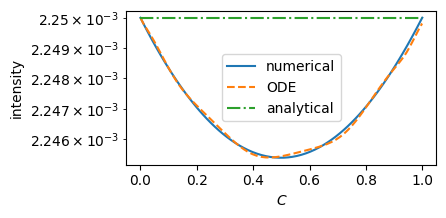

/home/vanregem/projects/tensor-circuit-torch/single_coupler_SPG/.venv/lib/python3.10/site-packages/matplotlib/transforms.py:2876: ComplexWarning: Casting complex values to real discards the imaginary part
  vmin, vmax = map(float, [vmin, vmax])


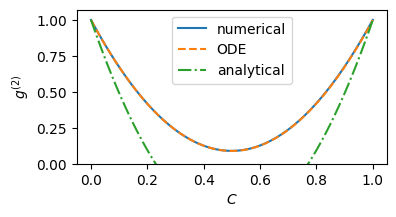

In [5]:
import matplotlib.pyplot as plt

x = np.sin(J * tlist) ** 2

plt.figure(figsize=(4,2))
plt.semilogy(x, n_BS_ts[:,1])
plt.semilogy(x, n_ODE, "--")
plt.semilogy(x, [na] * num_t, "-.")

plt.xlabel(r"$C$")
plt.ylabel("intensity")
plt.legend(["numerical", "ODE", "analytical"])
plt.show()

plt.figure(figsize=(4,2))
plt.plot(x, g2_BS_ts[:,1])
plt.plot(x, g2_ODE, "--")
plt.plot(x, g2_an, "-.")

plt.xlabel(r"$C$")
plt.ylabel("$g^{(2)}$")
plt.legend(["numerical", "ODE", "analytical"])
plt.ylim(bottom=np.maximum(np.min(g2_an), 0.))
plt.show()

# number distribution

Probability of signal: 0.004987377935893211
conditioned SP probability: 0.9975114829151034 vs. 0.9975020833324698 (coherent)


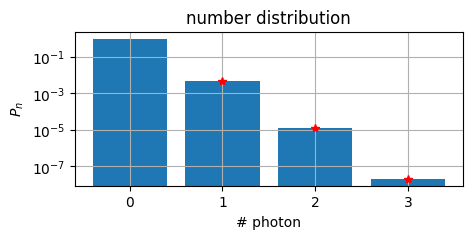

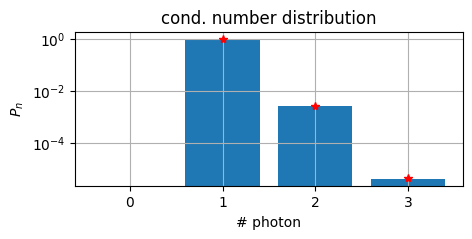

In [20]:
# find lowest g2 value
ind = np.argmin(g2_BS_ts[:,1])

# transform to S and AS modes -> application of pi/4 (50:50) BS
H_BS = H_BS_gen(np.pi/4.)
results = sesolve(H_BS, rho_ts[ind], [0, 1])

# compute number distributions
psi = results.states[-1]
Pn = ptrace(results.states[-1], 1).diag()
Pn_coh = coherent_dm(N, alpha=np.sqrt(na)).diag()

# conditioned probabilities
Pn_cond = Pn.copy()
Pn_cond[0] = 0.
Pn_cond = Pn_cond / Pn_cond.sum()

Pn_coh_cond = Pn_coh
Pn_coh_cond[0] = 0.
Pn_coh_cond = Pn_coh_cond / Pn_coh_cond.sum()

# print some info
print(f"Probability of signal: {1. - Pn[0]}")
print(f"conditioned SP probability: {Pn_cond[1]} vs. {Pn_coh_cond[1]} (coherent)")


# the plot
N_max = 4
plt.figure(figsize=(5,2))
plt.bar(range(N_max), Pn[:N_max])
plt.plot(range(N_max), Pn_coh[:N_max], "r*")
plt.yscale('log')
plt.xlabel('# photon')
plt.ylabel(r"$P_n$")
plt.xticks(range(N_max))
plt.grid(True)
plt.title("number distribution")

plt.figure(figsize=(5,2))
plt.bar(range(N_max), Pn_cond[:N_max])
plt.plot(range(N_max), Pn_coh_cond[:N_max], "r*")
plt.yscale('log')
plt.xlabel('# photon')
plt.ylabel(r"$P_n$")
plt.xticks(range(N_max))
plt.grid(True)
plt.title("cond. number distribution")
plt.show()

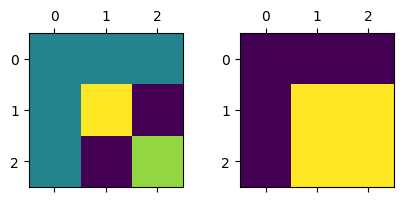

In [16]:
# Prepare AS arm signal cond. state
rhoR = ptrace(results.states[-1], 1)
rho_signal = ptrace((id_op - Pn_ops[1][0]) @ psi, 1).unit()
rho_signal_coh = coherent_dm(N, alpha=np.sqrt(na))

# Prepare coherent conditioned equivalent intensity
P_signal = qeye(100) - fock_dm(N,0)
rho_signal_coh = (P_signal @ rho_signal_coh @ P_signal.dag()).unit()


fig, ax = plt.subplots(1,2, figsize=(5,2))
ax[0].matshow(rho_signal.full().real[:3,:3])
ax[1].matshow(rho_signal_coh.full().real[:3,:3])

In [61]:
psi = results.states[-1]

rhoL = ptrace(psi, 0).full()
rhoR = ptrace(psi, 1).full()

rhoL_cond0 = ptrace((Pn_ops[1][0] @ psi).unit(), 0).full() # 1st index channel, 2nd ph. number
rhoL_cond1 = ptrace((Pn_ops[1][1] @ psi).unit(), 0).full() # 1st index channel, 2nd ph. number

state_bell = (tensor(fock(N,0), fock(N,1)) + tensor(fock(N,1), fock(N,0))).unit()
state_coh = tensor(coherent(N,alpha=np.sqrt(0.5)), coherent(N,alpha=np.sqrt(0.5)))

phase_shift = 0.1

# phase Hamiltonian
H_ph = create_H(J=0, U=0, Delta=[np.pi/2, 0.])
H_ph_pert = create_H(J=0, U=0, Delta=[np.pi/2 + phase_shift, 0.])

# coupler Hamiltonian
H_c = create_H(J=np.pi/4., U=0., Delta=0.)

FIs = []
for state in [state_bell, state_coh]:

    # apply phase shift
    results = mesolve(H_ph, state, tlist=[0.,1.])
    state_non_pert = results.states[-1]

    results = mesolve(H_ph_pert, state, tlist=[0.,1.])
    state_pert = results.states[-1]

    # run out-coupler
    results = mesolve(H_c, state_non_pert, tlist=[0.,1.])
    state_out = results.states[-1]
    P_out_full = np.abs(state_out.full()) ** 2
    P_out = np.array([P_out_full[0], np.sum(P_out_full[1:])])

    results = mesolve(H_c, state_pert, tlist=[0.,1.])
    state_pert_out = results.states[-1]
    P_pert_out_full = np.abs(state_pert_out.full()) ** 2
    P_pert_out = np.array([P_pert_out_full[0], np.sum(P_pert_out_full[1:])])

    FIs += [
        np.sum(P_out * (
            np.log(P_out + 1e-13) - np.log(P_pert_out + 1e-13)
            ) ** 2
            ) / phase_shift ** 2
            ]


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [63]:
[P_out_full[0], np.sum(P_out_full[1:])]

[array([0.]), np.float64(1.0)]

In [62]:
np.sum(P_out_full[1:])

np.float64(1.0)

In [40]:
P_out.reshape((N,N))[0,1]

# P = np.abs(state.full()) ** 2
# P.reshape((N,N))[0,1]

np.float64(2.940862684548514e-10)

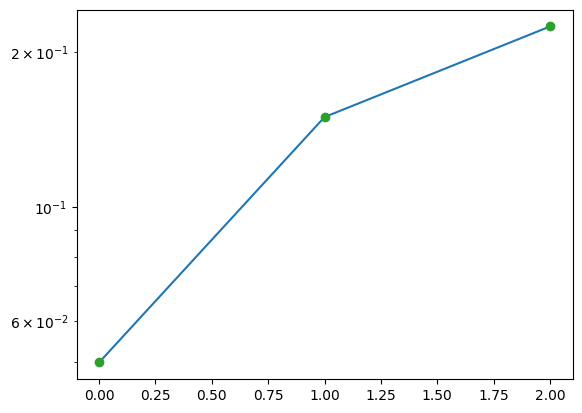

In [8]:
psi = results.states[-1]

rhoL = ptrace(psi, 0).full()
rhoR = ptrace(psi, 1).full()

rhoL_cond0 = ptrace((Pn_ops[1][0] @ psi).unit(), 0).full() # 1st index channel, 2nd ph. number
rhoL_cond1 = ptrace((Pn_ops[1][1] @ psi).unit(), 0).full() # 1st index channel, 2nd ph. number

plt.semilogy(np.diag(rhoL[:3]).real, "-")
plt.semilogy(np.diag(rhoL_cond0[:3]).real, "*")
plt.semilogy(np.diag(rhoL_cond1[:3]).real, "o")

plt.show()

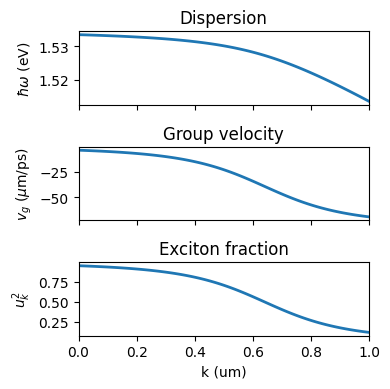

In [42]:
hbar_eV_ps = 6.582 * 1e-4 # hbar, converting energy to frequency

ki = 1.0
m = - 0.052
C = lambda k: 1.5165 + m*(k-ki)
X = lambda k: 1.5352 + 0*(k-ki)
OM = 0.008

# Definition of lower polariton branch
def omega_LP(k):

    Lowpol = 0.5*(C(k) + X(k)) - 0.5*((C(k) - X(k))**2 + 4*OM**2)**0.5

    return Lowpol

def vg_LP(k: float, dk: float=1e-3):
    """
    Lower-polariton group velocity, in eV * um / hbar = um / ps
    """
    return (omega_LP(k + dk/2.) - omega_LP(k - dk/2.)) / dk / hbar_eV_ps

def exciton_fraction(k):
    """ 
    The exciton fraction at given k (um^(-1))
    """

    theta_k = np.arctan(OM / (omega_LP(k) - C(k)))
    return np.cos(theta_k) ** 2


# k vector
k = np.linspace(0,1,100)

# dispersion
hbar_omega = omega_LP(k)

# group velocity
vg = vg_LP(k)
uk = exciton_fraction(k)

fig, ax = plt.subplots(3,1, figsize=(4,4), sharex=True)

ax[0].plot(k, hbar_omega, linewidth=2)
ax[1].plot(k, vg, linewidth=2)
ax[2].plot(k, uk, linewidth=2)
ax[0].set_title("Dispersion")
ax[1].set_title("Group velocity")
ax[2].set_title("Exciton fraction")
ax[0].set_ylabel(r"$\hbar \omega$ (eV)")
ax[1].set_ylabel(r"$v_g$ ($\mu$m/ps)")
ax[2].set_ylabel(r"$u^2_k$")
ax[-1].set_xlabel("k (um)")

for a in ax:
    a.set_xlim([k.min(), k.max()])

fig.tight_layout()